# pandaICT basic scenario and functionalities

This pages defines a very basic application scenario for pandaICT. It then lists the pandaICT functionalities needed for this scenario, which is meant to serve as a reference for early development. 


## Scenario

### pandapower network

We'll be using the simple example from the pp tutorial as obtained by

In [5]:
import pandapower as pp

net = pp.networks.example_simple()

This net has 7 buses, one 110/20 kV trafo and one load, sgen and gen each:

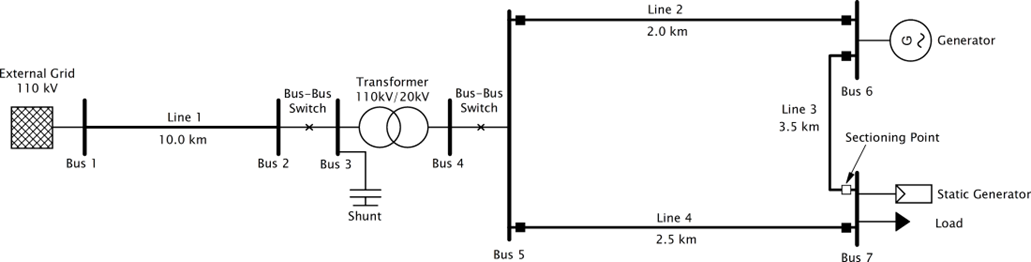

The trafo is equipped with a tap changer. The shunt is fixed. There are no timeseries included in the example. 

If we vary the infeed powers of the generators between 0..15 MVA / -12..12 MVar and consider both no-load and high-load (25 MVA) cases, we get some very extreme configuration with line loadings over 100%. E.g. line 2 is overloaded for multiple cases when Qsgen=-12 MVar, and line 1 is overloaded for multiple configurations when Pgen=12 MVA. Meanwhile, min/max voltage levels over all buses stay within 1 .. 1.05 p.U. for all cases. 

If the line lengths of line 2 and 4 are quadrupled, min/max voltages move between 0.935 .. 1.093 p.U. while line loadings look similar to before. When the line lengths stay original but line types are changed to the next weaker std type (NA2XS2Y 1x185 RM/25 12/20 kV), we still only get overloads if the absolute sgen reactive power exceeds 8. With the lines even weaker (NA2XS2Y 1x95 RM/25 12/20 kV), overloadings are possible with reactive power absolutes of 4 or less; notably, there are overloading cases with reactive powers of both generators being zero. Meanwhile voltages move between 0.996 .. 1.052 p.U. If line lengths are quadrupled in addition to that, line loadings would rise even more (up to 160%) and voltages would move between 0.91 .. 1.112 p.U.

To summarize, replacing the line types for lines 2 and 4 by NA2XS2Y 1x95 RM/25 12/20 kV while leaving line lengths unchanged would create an interesting use case for congestion management or a "Redispatch 2.0" scenario. A fixed cos phi could be set for both generators. To create a slightly more interesting scenario, it seems feasible to replace the gen by an sgen and treat the sgen at bus 6 as a wind farm, the one at bus 7 as PV plant. When cos phi for the generators is fixed to 0.98 and for the load to 0.95, line overloads may occur for certain load cases as soon as any of the generator's active powers exceeds 9 MVA. The trafo loading stays below 78% at all times. Voltages move between 0.99 .. 1.06 p.U.

The adapted network can be obtained by:

In [6]:
import pandapower as pp
net = pp.networks.example_simple()
pp.change_std_type(net,1,'NA2XS2Y 1x95 RM/25 12/20 kV','line')
pp.change_std_type(net,3,'NA2XS2Y 1x95 RM/25 12/20 kV','line')    
net.gen = net.gen.drop(0) # drop gen at bus 7        
pp.create_sgen(net, 5, p_mw=10, q_mvar=0, sn_mva=12, name="WPP", index=1) # create new 'PV' sgen at bus 7 
net.sgen.at[0,'name'] = 'PV' # make other sgen 'WPP' 
net.sgen.at[0,'q_mvar'] = 0 
net.load.at[0,'scaling'] = 1

### Timeseries

Timeseries for WPP and PV sgens are generated using renewable.ninja for locations near Hambach/Pfalz. There are already two wind power plants at the location and there is sufficient space for PV. Maximal peak powers of 12 MVA for both generators are chosen for generation of hourly timeseries. The cosphi is set to 1. For the load, the standard load profile G0-M is taken from the SimBench dataset. This contains quarter-hourly normalized active and reactive powers. Only the values at the full hours are taken and multiplied by 4 to obtain an hourly MW / MVar timeseries. 
A pp timeseries simulation was carried out with the resulting network. The resulting line loadings exceed 100% for multiple times in the year and both the lines that were weakened compared to the original network. The bus voltages stay between 0.992 .. 1,037 p.U. The max trafo loading is 60%.

The network including timeseries is stored as "UC4_simple.json" in the test folder under the recode/pandaict git.

### ICT network

To define the pandaICT model, an ICT infrastructure is added to the network according to the following graph. As for the ICTdevices, "CC" is the grid operator control center, "PQ" is a PQ meter, "PC" is an active power controller and "SC" is a switch controller. The PQ meters are supposed to be situated in a HV/MV substation together with Node 2. Node 3 is situated at Bus 6 and has a LAN connections to the Wind power plant PC which directly supports IEC 61850. Node 4 is situated at the PV plant main connection cabinet and is connected to its PC by a proprietary protocol. Node 5 is situated at the bus 7 substation and connected to the switch (controller) by a simple digital I/O. We assume that it's a power switch that may be operated under load. 

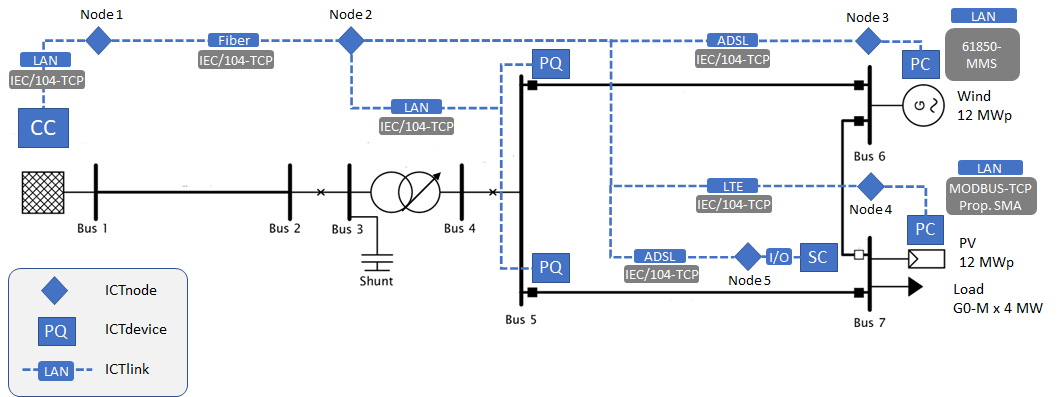


### Use case

Use case 4 is about different applications in grid operation, including redispatch and topology optimisation. pandaICT is to be used for calculating the reliability of ICT connections. Then, a one-year simulation is to be conducted. Finally, the the consumption/generation units is to be simulated by SIMONA within an OpSim based co-simulation. 
Each connection in the scenario contains three different protocols and physical media as our use case for reliability calculation.
In terms of operation simulation, the scenario allows for testing redispatch (WPP, PV) and topology change (switch) for congestion management of lines between bus 5 and bus 6 / bus 7. Here for, the CC should receive the line loadings from both PQ meters regularly or event-based (if e.g. an 80% threshold is exceeded). If a treshold is exceeded, it should react by derating the WPP and/or PV plant using the PCs. Closing the switch might be considered to mitigate the need for deration.

## pandaICT functionalities

The following pandaICT functionalities are needed for implementing this use case: 

- Data models and standard types for ICTnode, ICTdevice, ICTlink, ICTconnection including media / protocol definitions (Note: ICTlinks are point-to-point connections, ICTconnections are end-to-end)
- Default reliability and properties of named protocols and physical media 
- Connection / mapping between ICTdevices and sgens, lines and switches as well as ICTnodes and buses (to be used if applicable)
- Creation methods for ICTnodes, ICTdevices, ICTlink, ICTconnection
- Calculation of reliability for end-to-end connections (MTBF, Rate of information item loss, ??)
- Optional: topology methods, e.g. count ICTlinks for given ICTconnection, check if ICTconnection is available, calculate total latency for ICTconnections etc.
- Optional: semi-automated creation method for ICT net
- Optional: ICTnet integrity checking
- Optional: Standard information item types
- Optional: Definition of transmitted information items per time per ICTconnection 